# Лабораторная работа 1. Дискретное пространство состояний

**Вариант:** [RedBlueDoorEnv](https://minigrid.farama.org/environments/minigrid/RedBlueDoorEnv/) из библиотеки MiniGrid.

**Миссия агента:** «open the red door then the blue door» — сначала открыть красную дверь, потом синюю.

## Пункт 1. Библиотека окружений Gymnasium

### 1.0. Выбор конфигурации

У варианта две зарегистрированные конфигурации: `MiniGrid-RedBlueDoors-6x6-v0` и `MiniGrid-RedBlueDoors-8x8-v0`. В задании размер не указан, поэтому **выбираем 6x6**.

**Обоснование.** В пунктах 3–6 используются *табличные* методы (value iteration, Q-learning, SARSA): ценность хранится отдельно для каждого состояния, и каждое состояние нужно посетить много раз. Ниже (п. 1.4) мы посчитаем, что у 6x6 около 3 тыс. состояний. У 8x8 комната 6×6 вместо 4×4 и 36 расстановок дверей вместо 16, то есть состояний в 5–6 раз больше. Устройство задачи от этого не меняется, растёт только время обучения.

Сид фиксируем (`SEED = 0`), чтобы карта и все картинки воспроизводились при перезапуске ноутбука.

In [1]:
import copy
from collections import Counter, deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from gymnasium import Wrapper
from minigrid.core.actions import Actions
from minigrid.core.constants import IDX_TO_COLOR, IDX_TO_OBJECT, OBJECT_TO_IDX
from minigrid.wrappers import FullyObsWrapper  # импорт minigrid регистрирует среды MiniGrid-* в gymnasium

ENV_ID = "MiniGrid-RedBlueDoors-6x6-v0"
SEED = 0

### 1.1. Среда без обёрток

Создаём среду так, как она зарегистрирована, и смотрим на её пространства. `render_mode="rgb_array"`: `render()` возвращает картинку в виде массива, который рисуем через matplotlib (окно pygame в ноутбуке не нужно).

observation_space: Dict('direction': Discrete(4), 'image': Box(0, 255, (7, 7, 3), uint8), 'mission': MissionSpace(<function RedBlueDoorEnv._gen_mission at 0x000001B2D4C4E980>, None))
action_space:      Discrete(7)
сетка (width x height): 12 x 6
max_steps: 720
mission:   open the red door then the blue door
obs['image'].shape: (7, 7, 3)   obs['direction']: 1


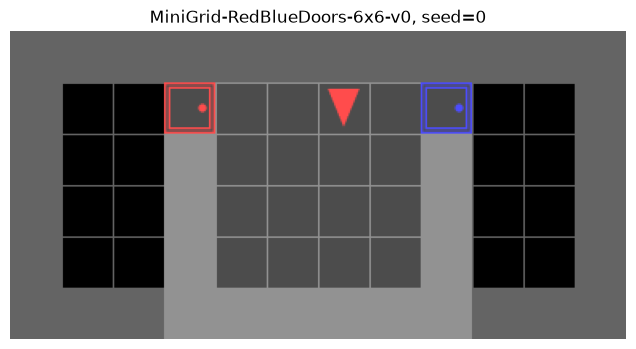

In [2]:
raw_env = gym.make(ENV_ID, render_mode="rgb_array")
obs, info = raw_env.reset(seed=SEED)
u = raw_env.unwrapped  # сама RedBlueDoorEnv под служебными обёртками gymnasium

print("observation_space:", raw_env.observation_space)
print("action_space:     ", raw_env.action_space)
print("сетка (width x height):", u.width, "x", u.height)
print("max_steps:", u.max_steps)
print("mission:  ", obs["mission"])
print("obs['image'].shape:", obs["image"].shape, "  obs['direction']:", obs["direction"])

plt.figure(figsize=(8, 4))
plt.imshow(raw_env.render())
plt.axis("off")
plt.title(f"{ENV_ID}, seed={SEED}")
plt.show()

**Что видим.**

- **Карта** 12×6 (ширина `2·size`). В центре комната 4×4, красная дверь в левой стене, синяя в правой. За дверями пустые «коридоры» 2×4. Позиции дверей по вертикали и стартовое положение агента выбираются случайно при каждом `reset`.
- **Наблюдение** — словарь из трёх полей:
  - `image` — закодированная картинка 7×7 **только перед агентом** (на рендере это светлая подсвеченная область; чёрные клетки — пол вне поля зрения);
  - `direction` — направление взгляда (0 →, 1 ↓, 2 ←, 3 ↑);
  - `mission` — текст задания. Он всегда один и тот же, поэтому в состояние его не включаем.
- **Частичная наблюдаемость.** По окну 7×7 агент не всегда видит обе двери и не знает, где именно стоит. Разные состояния мира могут давать одно и то же наблюдение, а табличным методам нужно, чтобы наблюдение однозначно задавало состояние. Поэтому дальше применяем `FullyObsWrapper` (п. 1.3).
- **Лимит шагов:** `max_steps = 20·size² = 720`. По его достижении эпизод обрывается (`truncated=True`).

### 1.2. Пространство действий

`Discrete(7)`. Смысл действий задан перечислением `minigrid.core.actions.Actions`:

In [3]:
for a in Actions:
    print(a.value, a.name)

0 left
1 right
2 forward
3 pickup
4 drop
5 toggle
6 done


В документации RedBlueDoorEnv действия `pickup`, `drop` и `done` помечены как *Unused*: на карте нет предметов, а `done` в `MiniGridEnv.step` ничего не делает. Проверим это: после каждого из них наблюдение не меняется, но счётчик шагов растёт.

In [4]:
obs0, _ = raw_env.reset(seed=SEED)
for a in [Actions.pickup, Actions.drop, Actions.done]:
    obs1, r, term, trunc, _ = raw_env.step(a)
    same = np.array_equal(obs0["image"], obs1["image"]) and obs0["direction"] == obs1["direction"]
    print(f"{a.name:7s}: наблюдение не изменилось = {same}, r = {r}, step_count = {raw_env.unwrapped.step_count}")

# Действия, которые реально меняют состояние среды
USEFUL_ACTIONS = [int(Actions.left), int(Actions.right), int(Actions.forward), int(Actions.toggle)]
ACTION_NAMES = {a.value: a.name for a in Actions}
print("Полезные действия:", [ACTION_NAMES[a] for a in USEFUL_ACTIONS])

pickup : наблюдение не изменилось = True, r = 0, step_count = 1
drop   : наблюдение не изменилось = True, r = 0, step_count = 2
done   : наблюдение не изменилось = True, r = 0, step_count = 3
Полезные действия: ['left', 'right', 'forward', 'toggle']


**Вывод.** Значимых действий четыре: `left` и `right` (поворот на 90°), `forward` (шаг вперёд, если клетка свободна или там открытая дверь) и `toggle` (открыть или закрыть дверь перед собой). Остальные три — это «стоять на месте», они только тратят шаг. В пунктах 3–6 будем перебирать только `USEFUL_ACTIONS`: таблица Q становится почти вдвое меньше (4 действия вместо 7), а оптимальная стратегия не меняется, потому что бесполезное действие никогда не может быть лучше полезного.

### 1.3. Обёртка `FullyObsWrapper`

Обёртка заменяет `image` на закодированную **всю** сетку. Каждая клетка — тройка `(OBJECT, COLOR, STATE)`:

- `OBJECT`: 1 — пусто, 2 — стена, 4 — дверь, 10 — агент;
- `COLOR`: 0 — red, 2 — blue, 5 — grey (у стен);
- `STATE`: для двери 0 — открыта, 1 — закрыта, 2 — заперта; в клетке агента — его направление.

Массив индексируется как `image[x][y]`, поэтому при печати транспонируем (`.T`), чтобы строки соответствовали `y`, как на картинке.

In [5]:
env = FullyObsWrapper(gym.make(ENV_ID, render_mode="rgb_array"))
obs, _ = env.reset(seed=SEED)
print("observation_space['image']:", env.observation_space["image"])
print("obs['image'].shape:", obs["image"].shape)


def show_layers(obs):
    # Три слоя кодировки; .T — чтобы строки были y, столбцы x (как на рендере)
    for k, name in enumerate(["OBJECT", "COLOR", "STATE"]):
        print(f"--- {name} ---")
        print(obs["image"][:, :, k].T)


def ascii_map(obs):
    # Наглядная карта: # стена, . пусто, R/B закрытая красная/синяя дверь, r/b открытая, стрелка — агент
    img = obs["image"]
    width, height, _ = img.shape
    rows = []
    for y in range(height):
        row = ""
        for x in range(width):
            obj, color, state = img[x, y]
            name = IDX_TO_OBJECT[obj]
            if name == "agent":
                row += ">v<^"[state]
            elif name == "door":
                letter = "R" if IDX_TO_COLOR[color] == "red" else "B"
                row += letter if state == 1 else letter.lower()
            else:
                row += {"wall": "#", "empty": "."}[name]
        rows.append(row)
    print("\n".join(rows))


show_layers(obs)
print("--- карта ---")
ascii_map(obs)

observation_space['image']: Box(0, 255, (12, 6, 3), uint8)
obs['image'].shape: (12, 6, 3)
--- OBJECT ---
[[ 2  2  2  2  2  2  2  2  2  2  2  2]
 [ 2  1  1  4  1  1 10  1  4  1  1  2]
 [ 2  1  1  2  1  1  1  1  2  1  1  2]
 [ 2  1  1  2  1  1  1  1  2  1  1  2]
 [ 2  1  1  2  1  1  1  1  2  1  1  2]
 [ 2  2  2  2  2  2  2  2  2  2  2  2]]
--- COLOR ---
[[5 5 5 5 5 5 5 5 5 5 5 5]
 [5 0 0 0 0 0 0 0 2 0 0 5]
 [5 0 0 5 0 0 0 0 5 0 0 5]
 [5 0 0 5 0 0 0 0 5 0 0 5]
 [5 0 0 5 0 0 0 0 5 0 0 5]
 [5 5 5 5 5 5 5 5 5 5 5 5]]
--- STATE ---
[[0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 1 0 1 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0]]
--- карта ---
############
#..R..v.B..#
#..#....#..#
#..#....#..#
#..#....#..#
############


**Что видим.** В слое `OBJECT` стены (2), пустые клетки (1), две двери (4) и агент (10). У пустых клеток `COLOR = 0`: это не «красный», а заглушка, потому что пустая клетка кодируется как `(1, 0, 0)`. В слое `STATE` у обеих дверей стоит 1 (закрыты), а в клетке агента его направление. Клетку под агентом обёртка затирает тройкой `(10, red, dir)`. Это не теряет информацию: агент может стоять только на пустой клетке или в проёме *открытой* двери.

**Почему такое наблюдение годится как состояние MDP.** В пункте 3 задание предлагает ключ `image + direction + carrying`. Проверим, что он содержит всё, от чего зависит будущее:

- положение агента и обеих дверей видно в `image`;
- открыта ли каждая дверь — тоже в `image` (слой `STATE`), так что отдельно добавлять «информацию о дверях» не нужно;
- направление есть и в `image`, и в `direction`;
- `carrying` в этой среде всегда `None` (предметов нет), его оставляем ради совместимости с формулой из задания.

Не хватает только счётчика шагов `step_count`, а от него зависит награда. К этому вернёмся в п. 1.6.

In [6]:
def state_key(obs, env):
    # Ключ состояния из задания (пункт 3): вся сетка + направление + что несёт агент
    return str(obs["image"].flatten().tolist() + [obs["direction"], env.unwrapped.carrying])

### 1.4. Размер пространства состояний

`observation_space` формально огромный: `Box(0, 255, (12, 6, 3))`. Но реально достижимых состояний мало, и их можно перебрать.

**Расстановки и старты.** Переберём много сидов и посчитаем разные расстановки дверей и стартовые положения агента.

In [7]:
layouts, starts = set(), set()
for seed in range(2000):
    o, _ = env.reset(seed=seed)
    doors = np.argwhere(o["image"][:, :, 0] == OBJECT_TO_IDX["door"])
    layouts.add(tuple(map(tuple, doors.tolist())))
    starts.add((tuple(map(int, env.unwrapped.agent_pos)), int(env.unwrapped.agent_dir)))
print("Различных расстановок дверей:", len(layouts), "(красная: 4 варианта по y, синяя: 4 варианта по y)")
print("Различных стартов агента:    ", len(starts), "(16 клеток комнаты x 4 направления)")

Различных расстановок дверей: 16 (красная: 4 варианта по y, синяя: 4 варианта по y)
Различных стартов агента:     64 (16 клеток комнаты x 4 направления)


**Достижимые состояния при одной расстановке.** У MiniGrid нет явной модели переходов $P(s'|s,a)$, как у `mdp.py` из семинара. Зато среду можно скопировать (`copy.deepcopy(env)`), сделать в копии шаг и посмотреть, куда она попала. На этом приёме будет держаться и value iteration в пункте 3. Здесь используем его для обхода в ширину (BFS) всех состояний, достижимых из старта.

In [8]:
def reachable_states(env, obs, actions=USEFUL_ACTIONS):
    # BFS по состояниям: ключ -> копия окружения в этом состоянии
    start = state_key(obs, env)
    states = {start: copy.deepcopy(env)}
    queue = deque([start])
    n_terminal_transitions = 0
    while queue:
        e = states[queue.popleft()]
        for a in actions:
            e2 = copy.deepcopy(e)  # шаг делаем в копии, чтобы не испортить исходное состояние
            o, r, term, trunc, _ = e2.step(a)
            if term:
                n_terminal_transitions += 1
                continue
            k = state_key(o, e2)
            if k not in states:
                states[k] = e2
                queue.append(k)
    return states, n_terminal_transitions


obs, _ = env.reset(seed=SEED)
states, n_term = reachable_states(env, obs)
print("Достижимых нетерминальных состояний:", len(states))
print("Переходов в терминальные состояния: ", n_term)


def category(e):
    u = e.unwrapped
    x = u.agent_pos[0]
    red = "красная открыта" if u.red_door.is_open else "красная закрыта"
    where = "левый коридор" if x < u.size // 2 else ("проём красной двери" if x == u.size // 2 else "комната")
    return red, where


for (red, where), n in sorted(Counter(category(e) for e in states.values()).items()):
    print(f"  {red:16s} | агент: {where:20s} | {n:3d} = {n // 4:2d} кл. x 4 направления")
print("Всего нетерминальных состояний по всем расстановкам: 16 x", len(states), "=", 16 * len(states))

Достижимых нетерминальных состояний: 196
Переходов в терминальные состояния:  2
  красная закрыта  | агент: комната              |  64 = 16 кл. x 4 направления
  красная закрыта  | агент: левый коридор        |  32 =  8 кл. x 4 направления
  красная открыта  | агент: комната              |  64 = 16 кл. x 4 направления
  красная открыта  | агент: левый коридор        |  32 =  8 кл. x 4 направления
  красная открыта  | агент: проём красной двери  |   4 =  1 кл. x 4 направления
Всего нетерминальных состояний по всем расстановкам: 16 x 196 = 3136


**Разбор числа 196.**

| Красная дверь | Где агент | Клеток | Состояний |
|---|---|---|---|
| закрыта | комната | 16 | 64 |
| открыта | комната | 16 | 64 |
| открыта | проём двери | 1 | 4 |
| открыта | левый коридор | 8 | 32 |
| закрыта | левый коридор (вышел и закрыл за собой) | 8 | 32 |

Синяя дверь во всех нетерминальных состояниях закрыта: стоит её открыть, и эпизод заканчивается. В правый коридор агент поэтому попасть не может.

Переходов в терминальные состояния всего 2. Оба — это `toggle` из клетки перед синей дверью лицом к ней: при открытой красной это успех, при закрытой — провал. Из 196·4 = 784 пар (состояние, действие) награду может дать только одна, поэтому награда такая разреженная. Для разных расстановок множества состояний не пересекаются (двери в `image` стоят в разных местах), так что всего $16 \cdot 196 = 3136$ состояний. Это легко помещается в словарь, поэтому в пункте 3 можно перебирать все состояния, а не использовать вариант для «очень многих состояний».

### 1.5. Несколько шагов с картинками: как меняется награда

Награда в `RedBlueDoorEnv.step` (см. исходник `minigrid/envs/redbluedoors.py`):

- открыта **синяя** дверь, когда **красная уже открыта** → успех, $r = 1 - 0.9 \cdot \frac{step\_count}{max\_steps}$, эпизод завершается (`terminated=True`);
- открыта синяя дверь, когда красная закрыта → провал, $r = 0$, эпизод тоже завершается;
- на всех остальных шагах $r = 0$.

Помощник ниже проигрывает заданную последовательность действий, печатает таблицу наград и рисует кадр после каждого шага.

In [9]:
def run_actions(env, actions, seed=SEED, title="", draw=True, ncols=4):
    obs, _ = env.reset(seed=seed)
    frames = [(env.render(), "старт")]
    total = 0
    print(f"{'шаг':>3} | {'действие':8s} | {'r':>6s} | term  | trunc")
    for t, a in enumerate(actions, 1):
        obs, r, term, trunc, _ = env.step(a)
        total += r
        print(f"{t:3d} | {ACTION_NAMES[a]:8s} | {r:6.4f} | {term!s:5s} | {trunc}")
        frames.append((env.render(), f"{t}: {ACTION_NAMES[a]}, r={r:.4f}"))
        if term or trunc:
            break
    print("Суммарная награда:", round(total, 4))
    if draw:
        nrows = -(-len(frames) // ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.2 * nrows))
        for ax in axes.flat:
            ax.axis("off")
        for ax, (img, caption) in zip(axes.flat, frames):
            ax.imshow(img)
            ax.set_title(caption, fontsize=10)
        fig.suptitle(title)
        plt.tight_layout()
        plt.show()
    return total


L, R, F, T = int(Actions.left), int(Actions.right), int(Actions.forward), int(Actions.toggle)

**(а) Успешный сценарий.** На карте сида 0 (см. п. 1.3) агент стоит в клетке (6, 1) и смотрит вниз, красная дверь в (3, 1), синяя в (8, 1), все в верхнем ряду комнаты. План: повернуться налево (`right` из «вниз» даёт «влево»), дойти до красной двери, открыть её, развернуться, дойти до синей и открыть её. Получается 10 действий, и короче нельзя. Нужно 1 поворот к красной двери, 2 шага до неё, 1 `toggle`, 2 поворота для разворота, 3 шага до синей двери и ещё 1 `toggle`: $1+2+1+2+3+1 = 10$.

шаг | действие |      r | term  | trunc
  1 | right    | 0.0000 | False | False
  2 | forward  | 0.0000 | False | False
  3 | forward  | 0.0000 | False | False
  4 | toggle   | 0.0000 | False | False
  5 | left     | 0.0000 | False | False
  6 | left     | 0.0000 | False | False
  7 | forward  | 0.0000 | False | False
  8 | forward  | 0.0000 | False | False
  9 | forward  | 0.0000 | False | False
 10 | toggle   | 0.9875 | True  | False
Суммарная награда: 0.9875


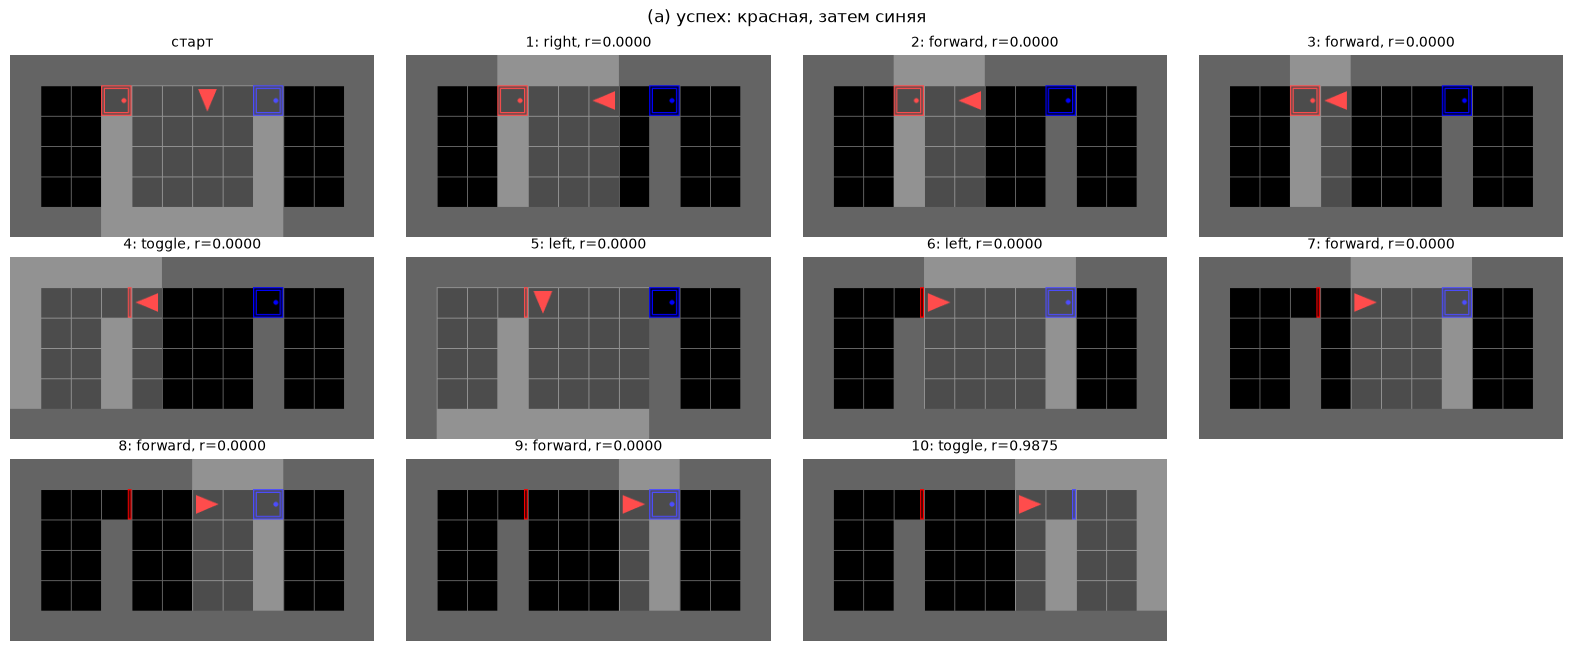

По формуле: 1 - 0.9 * 10 / 720 = 0.9875


In [10]:
success = [R, F, F, T, L, L, F, F, F, T]
r_a = run_actions(env, success, title="(а) успех: красная, затем синяя")
print("По формуле: 1 - 0.9 * 10 / 720 =", round(1 - 0.9 * 10 / env.unwrapped.max_steps, 4))

Награда нулевая на всех шагах, кроме последнего. Открытие красной двери (шаг 4) **не награждается**, хотя это необходимый подшаг. Награда разреженная: агенту придётся самому выяснить, что открытие красной двери полезно. В пунктах 2–3 это видно по тому, как ценность «растекается» назад от финала.

**(б) Провал: синяя дверь первой.** Из того же старта повернуться направо, сделать шаг и открыть синюю дверь.

шаг | действие |      r | term  | trunc
  1 | left     | 0.0000 | False | False
  2 | forward  | 0.0000 | False | False
  3 | toggle   | 0.0000 | True  | False
Суммарная награда: 0


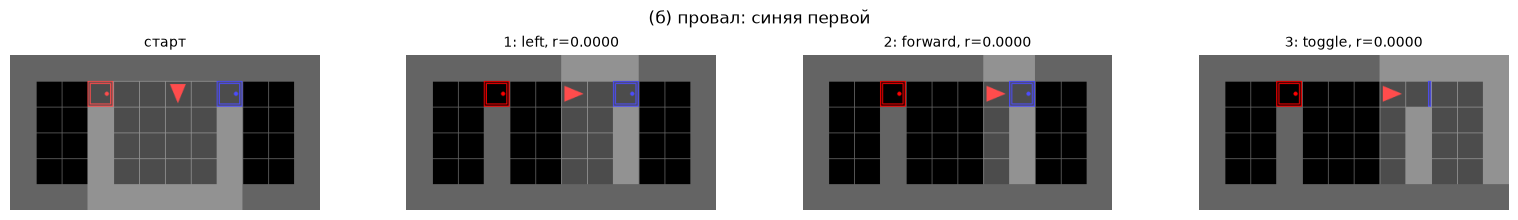

In [11]:
fail = [L, F, T]
r_b = run_actions(env, fail, title="(б) провал: синяя первой")

Эпизод завершился (`terminated=True`) с наградой 0. Провал и обычный шаг дают одинаковую награду, но провал *обрывает* эпизод, и награду 1 в нём уже не получить. Поэтому ценность такого действия будет нулевой.

Замечание: красную дверь можно открывать и закрывать сколько угодно. Если закрыть её и потом открыть синюю, это тоже провал: среда проверяет, открыта ли красная дверь *в момент* открытия синей.

**(в) Тот же успех с лишними действиями.** Перед успешным сценарием добавим полный оборот на месте (4 × `left`): агент возвращается в то же самое состояние, но тратит 4 шага.

In [12]:
detour = [L, L, L, L] + success
r_c = run_actions(env, detour, title="(в) успех с полным оборотом в начале", draw=False)
print("По формуле: 1 - 0.9 * 14 / 720 =", round(1 - 0.9 * 14 / env.unwrapped.max_steps, 4))

шаг | действие |      r | term  | trunc
  1 | left     | 0.0000 | False | False
  2 | left     | 0.0000 | False | False


  3 | left     | 0.0000 | False | False
  4 | left     | 0.0000 | False | False
  5 | right    | 0.0000 | False | False
  6 | forward  | 0.0000 | False | False
  7 | forward  | 0.0000 | False | False
  8 | toggle   | 0.0000 | False | False
  9 | left     | 0.0000 | False | False
 10 | left     | 0.0000 | False | False
 11 | forward  | 0.0000 | False | False
 12 | forward  | 0.0000 | False | False
 13 | forward  | 0.0000 | False | False
 14 | toggle   | 0.9825 | True  | False
Суммарная награда: 0.9825
По формуле: 1 - 0.9 * 14 / 720 = 0.9825


### 1.6. Почему исходная награда не марковская

Сравним **последний переход** в сценариях (а) и (в): состояние до шага, действие и состояние после.

In [13]:
def last_transition(env, actions, seed=SEED):
    obs, _ = env.reset(seed=seed)
    for a in actions[:-1]:
        obs, *_ = env.step(a)
    s = state_key(obs, env)
    obs2, r, *_ = env.step(actions[-1])
    return s, actions[-1], state_key(obs2, env), r


s1, a1, s1_next, r1 = last_transition(env, success)
s2, a2, s2_next, r2 = last_transition(env, detour)
print("s одинаковые: ", s1 == s2)
print("a одинаковые: ", a1 == a2)
print("s' одинаковые:", s1_next == s2_next)
print("r:", round(r1, 4), "vs", round(r2, 4))

s одинаковые:  True
a одинаковые:  True
s' одинаковые: True
r: 0.9875 vs 0.9825


Один и тот же переход $(s, a, s')$ дал разные награды. Награда зависит от `step_count`, а его нет в наблюдении. Значит, функции $r(s, a, s')$, которая нужна в уравнении Беллмана $V(s) = \max_a [r(s,a,s') + \gamma V(s')]$, просто не существует: процесс с таким состоянием **не марковский**.

Это можно исправить двумя способами:

1. Добавить номер шага в состояние. Тогда пространство состояний вырастет примерно в 720 раз.
2. Убрать зависимость награды от времени. Именно это предлагает задание.

### 1.7. Обёртка `BinaryRewardWrapper`

Класс взят из задания без изменений: любая ненулевая награда превращается в 1.

In [14]:
class BinaryRewardWrapper(Wrapper):
    def step(self, action):
        observation, reward, terminated, truncated, info = self.env.step(action)
        bin_reward = 1 if reward != 0 else 0
        return observation, bin_reward, terminated, truncated, info


def make_env():
    # Окружение, с которым работаем во всех следующих пунктах
    return BinaryRewardWrapper(FullyObsWrapper(gym.make(ENV_ID, render_mode="rgb_array")))


env = make_env()
print("(а) успех:")
run_actions(env, success, draw=False)
print("\n(в) успех с оборотом:")
run_actions(env, detour, draw=False)
print("\n(б) провал:")
run_actions(env, fail, draw=False)
s1, a1, s1_next, r1 = last_transition(env, success)
s2, a2, s2_next, r2 = last_transition(env, detour)
print("\nТот же последний переход теперь даёт одинаковую награду:", r1, "==", r2)

(а) успех:
шаг | действие |      r | term  | trunc
  1 | right    | 0.0000 | False | False
  2 | forward  | 0.0000 | False | False
  3 | forward  | 0.0000 | False | False
  4 | toggle   | 0.0000 | False | False
  5 | left     | 0.0000 | False | False
  6 | left     | 0.0000 | False | False
  7 | forward  | 0.0000 | False | False
  8 | forward  | 0.0000 | False | False
  9 | forward  | 0.0000 | False | False
 10 | toggle   | 1.0000 | True  | False
Суммарная награда: 1

(в) успех с оборотом:
шаг | действие |      r | term  | trunc
  1 | left     | 0.0000 | False | False
  2 | left     | 0.0000 | False | False
  3 | left     | 0.0000 | False | False
  4 | left     | 0.0000 | False | False
  5 | right    | 0.0000 | False | False
  6 | forward  | 0.0000 | False | False
  7 | forward  | 0.0000 | False | False
  8 | toggle   | 0.0000 | False | False
  9 | left     | 0.0000 | False | False
 10 | left     | 0.0000 | False | False
 11 | forward  | 0.0000 | False | False
 12 | forward  | 0.0000 |

**Почему обёртка корректна.**

- **Бинаризация ничего не смешивает.** В этой среде ненулевую награду даёт только успех: провал и обычные шаги и так дают 0. Новая награда равна 1 ровно в случае успеха и зависит только от перехода $(s, a, s')$, так что процесс становится марковским.
- **Стремление к короткому пути не теряется.** Раньше скорость поощрялась множителем $1 - 0.9 \cdot step/720$. Теперь её обеспечит дисконт $\gamma < 1$ в пунктах 2–6: успех через $k$ шагов стоит $\gamma^{k-1}$, и чем путь короче, тем ценность больше.
- **Порядок обёрток не важен.** `FullyObsWrapper` меняет только наблюдение, `BinaryRewardWrapper` только награду. Мы ставим `FullyObsWrapper` внутрь, потому что он наследуется от `ObservationWrapper` и работает с наблюдением сразу после среды.
- **Обрыв по лимиту.** Если за 720 шагов не дойти до цели, эпизод обрывается с наградой 0 и `truncated=True`. Это не терминальное состояние MDP (`terminated=False`), а внешнее прерывание, и при обучении его нужно отличать от `terminated`.

### Итоги пункта 1

1. **Среда:** `MiniGrid-RedBlueDoors-6x6-v0`, сетка 12×6, комната 4×4. 16 расстановок дверей, 64 стартовых положения.
2. **Действия:** `Discrete(7)`, но полезны только 4 (`left`, `right`, `forward`, `toggle`). `pickup`, `drop` и `done` ничего не делают.
3. **Наблюдение:** без обёрток видно только окно 7×7 перед агентом, то есть среда частично наблюдаема. С `FullyObsWrapper` видна вся сетка (12, 6, 3), включая состояния дверей. Ключ `image + direction + carrying` однозначно задаёт состояние мира, кроме счётчика шагов.
4. **Пространство состояний:** 196 нетерминальных состояний на расстановку, всего 3136. Это легко перебрать, поэтому в пункте 3 подходит полный перебор.
5. **Награда:** разреженная, есть только за успех и уменьшается с числом шагов. Из-за этого она не марковская: один и тот же переход даёт разную награду. `BinaryRewardWrapper` превращает её в индикатор успеха, а предпочтение коротких путей переходит к дисконту $\gamma$.
6. **Инструмент для дальнейших пунктов:** `make_env()`, `state_key()`, `USEFUL_ACTIONS` и приём «шаг в `deepcopy(env)`» вместо модели переходов.

## Пункт 2. Оценка ценности состояний вручную

### 2.0. Постановка

Метод последовательных приближений для уравнения Беллмана:

$$V_{i+1}(s) = \max_a \big[\, r(s,a,s') + \gamma V_i(s') \,\big]$$

**Почему формула именно такая.** В общем случае внутри стоит мат. ожидание по следующему состоянию: $\sum_{s'} P(s'|s,a)\,[r + \gamma V_i(s')]$. Наша среда **детерминированная**: из состояния $s$ действие $a$ всегда ведёт в одно и то же $s'$. Поэтому сумма вырождается в одно слагаемое и остаётся просто $\max_a$.

**Параметры.**

- $\gamma = 0.9$, как в семинаре `seminar_vi.ipynb`. Любое $0<\gamma<1$ подходит; при 0.9 степени $\gamma^k$ хорошо различимы на глаз: 1, 0.9, 0.81.
- $V_0(s) = 0$ для всех $s$. Это означает: «пока ничего не знаем о ценностях». Сходимость от начального приближения не зависит, а с нулём легко считать руками.
- **Терминальные состояния** (эпизод окончен, успехом или провалом) имеют $V = 0$, потому что после них наград больше не будет. Поэтому для перехода в терминальное $s'$ остаётся только $r$.
- Награда **бинарная** (после `BinaryRewardWrapper` из п. 1.7): $r = 1$ только за открытие синей двери при открытой красной, иначе 0.

**Карта.** Считаем для сида 0 из п. 1.3:

```
x:  0 1 2 3 4 5 6 7 8 9 10 11
    # # # # # # # # # # #  #     y=0
    # . . R . . v . B . .  #     y=1
    # . . # . . . . # . .  #     y=2
    # . . # . . . . # . .  #     y=3
    # . . # . . . . # . .  #     y=4
    # # # # # # # # # # #  #     y=5
```

Красная дверь в (3, 1), синяя в (8, 1). Состояние записываем как **(x, y, направление, красная дверь)**, направления: → (0), ↓ (1), ← (2), ↑ (3).

### 2.1. Итерация 1: $V_1$

Так как $V_0 \equiv 0$, формула упрощается: $V_1(s) = \max_a r(s,a,s')$, то есть ценность равна **лучшей мгновенной награде** из этого состояния.

Награда 1 бывает только при `toggle` синей двери, когда красная уже открыта. Чтобы `toggle` подействовал на синюю дверь (8, 1), агент должен стоять **перед ней** в клетке (7, 1) и **смотреть на неё**, то есть вправо. Получаем единственное подходящее состояние, назовём его **S\***:

| Состояние | Лучшее действие | $V_1$ |
|---|---|---|
| **S\*** = (7, 1, →, открыта) | `toggle` → r = 1, эпизод окончен | **1** |
| все остальные | — | 0 |

То же положение, но с **закрытой** красной дверью даёт `toggle` → провал, r = 0, поэтому там $V_1 = 0$.

### 2.2. Итерация 2: $V_2$

$V_2(s) = \max_a [r + 0.9 \cdot V_1(s')]$. Ненулевой $V_1$ есть только у S\*, поэтому $V_2(s) > 0$ возможно лишь в двух случаях: либо $s$ сам даёт награду (это S\*), либо какое-то действие **переводит $s$ в S\***.

**Кто за один шаг попадает в S\* = (7, 1, →, открыта)?** Перебираем действия:

| Откуда | Действие | Почему попадаем в S\* |
|---|---|---|
| (7, 1, ↓, открыта) | `left` | смотрел вниз, повернулся налево → смотрит вправо |
| (7, 1, ↑, открыта) | `right` | смотрел вверх, повернулся направо → смотрит вправо |
| (6, 1, →, открыта) | `forward` | шагнул вправо из (6, 1) в (7, 1) |

`toggle` в S\* привести не может: он меняет дверь перед агентом, а не его положение.

Значения:

| Состояние | Лучшее действие | $V_2$ |
|---|---|---|
| S\* = (7, 1, →) | `toggle`: $1 + 0.9 \cdot 0 = 1$ (остальные действия дают не больше 0) | **1** |
| (7, 1, ↓) | `left`: $0 + 0.9 \cdot V_1(S^*) = 0.9$ | **0.9** |
| (7, 1, ↑) | `right`: $0 + 0.9 \cdot 1$ | **0.9** |
| (6, 1, →) | `forward`: $0 + 0.9 \cdot 1$ | **0.9** |

Все со **открытой** красной дверью; остальные состояния — 0.

### 2.3. Итерация 3: $V_3$

$V_3(s) = \max_a [r + 0.9 \cdot V_2(s')]$. Новые ненулевые значения появятся у состояний, которые за один шаг попадают в одно из трёх состояний с $V_2 = 0.9$. Их значение будет $0.9 \cdot 0.9 = 0.81$.

**Кто попадает в (7, 1, ↓)?**

- (7, 1, ←) через `left`;
- (7, 0, ↓) через `forward` — но (7, 0) это стена, такого состояния нет;
- S\* через `right`, но у S\* значение уже 1 и больше.

**Кто попадает в (7, 1, ↑)?**

- (7, 1, ←) через `right`, то же состояние, что выше;
- (7, 2, ↑) через `forward`: шаг вверх из (7, 2) в (7, 1).

**Кто попадает в (6, 1, →)?**

- (6, 1, ↑) через `right`;
- (6, 1, ↓) через `left`;
- (5, 1, →) через `forward`.

Новых состояний 5: (7, 1, ←), (7, 2, ↑), (6, 1, ↑), (6, 1, ↓), (5, 1, →).

Значения уже найденных состояний **не растут**. Например, у (7, 1, ↓): `left` даёт $0.9 \cdot V_2(S^*) = 0.9$, а `forward` ведёт в (7, 2, ↓) с $V_2 = 0$. Максимум по-прежнему 0.9. Из этих состояний до награды нельзя добраться быстрее, чем мы уже учли.

#### Ответ на вопрос задания: для каких состояний $V_3 \neq 0$

Ненулевых значений **9**, во всех красная дверь открыта:

| № | Позиция агента | Направление | Шагов до успеха | $V_3$ |
|---|---|---|---|---|
| 1 | (7, 1) | → | 1 | **1** |
| 2 | (7, 1) | ↓ | 2 | **0.9** |
| 3 | (7, 1) | ↑ | 2 | **0.9** |
| 4 | (6, 1) | → | 2 | **0.9** |
| 5 | (7, 1) | ← | 3 | **0.81** |
| 6 | (7, 2) | ↑ | 3 | **0.81** |
| 7 | (6, 1) | ↑ | 3 | **0.81** |
| 8 | (6, 1) | ↓ | 3 | **0.81** |
| 9 | (5, 1) | → | 3 | **0.81** |

**Для любой расстановки дверей** (синяя дверь в строке $y_B$) картина та же, только сдвинутая по вертикали. Если $y_B$ — средняя строка (2 или 3), добавляется ещё состояние $(7, y_B-1, ↓)$, потому что сверху от двери появляется клетка. Тогда ненулевых значений **10**: 1 + 3 + 6. Для крайних строк (1 или 4) их **9**, как у нас.

**Почему нет ни одного состояния с закрытой красной дверью.** Чтобы победить с закрытой красной, её нужно сначала открыть, а это возможно только из клетки (4, 1) рядом с ней. Оттуда до синей двери ещё минимум 6 шагов, так что за 3 итерации ценность туда не «дотечёт».

### 2.4. Закономерность: ценность распространяется «волной»

Таблица подсказывает общее правило. В детерминированной среде с единственной наградой в конце:

$$V_k(s) = \begin{cases} \gamma^{\,d(s)-1}, & d(s) \le k \\ 0, & d(s) > k \end{cases}$$

где $d(s)$ — минимальное число шагов от $s$ до успеха.

Каждая итерация продвигает «фронт» ненулевых ценностей **на один шаг назад** от финиша:
- после итерации $k$ известны ценности всех состояний, из которых можно победить не более чем за $k$ шагов;
- чем дальше состояние, тем меньше ценность: множитель $\gamma$ за каждый лишний шаг.

Следствие для пункта 3: старт сида 0 в 10 шагах от успеха (п. 1.5), поэтому его ценность станет ненулевой только на **10-й** итерации и будет равна $0.9^9 \approx 0.387$. Самые далёкие состояния, например агент в левом коридоре за закрытой дверью, потребуют ещё больше итераций.

### 2.5. Проверка ручного расчёта программой

Ручной расчёт выше — основной ответ пункта. Ниже **проверка**: те же три итерации делает программа по всем 196 состояниям сида 0.

- Состояния берём из BFS `reachable_states()` (п. 1.4).
- Для каждой пары (состояние, действие) один раз делаем шаг в `deepcopy` и запоминаем $(r, s')$ — это таблица переходов, наша «модель» среды. Терминальный $s'$ записываем как `None`: его ценность 0.
- $V$ храним в словаре: отсутствующий ключ = 0, как требует задание.
- Обновление **синхронное**: $V_{i+1}$ считается целиком по старому $V_i$, как и в ручном расчёте.

Полноценная value iteration до сходимости, с обходом состояний по заданию, — это пункт 3.

In [15]:
GAMMA = 0.9


def build_transitions(states, actions):
    # (ключ s, действие a) -> (r, ключ s'), где s' = None, если эпизод закончился
    T = {}
    for k, e in states.items():
        for a in actions:
            e2 = copy.deepcopy(e)
            o, r, term, trunc, _ = e2.step(a)
            T[k, a] = (r, None if term else state_key(o, e2))
    return T


def q_value(V, T, k, a, gamma):
    r, k_next = T[k, a]
    return r + (gamma * V.get(k_next, 0) if k_next is not None else 0)


def bellman_sweep(V, states, T, actions, gamma):
    # Одна синхронная итерация: V_{i+1}(s) = max_a [r + gamma * V_i(s')]
    return {k: max(q_value(V, T, k, a, gamma) for a in actions) for k in states}


def describe(e):
    # Человекочитаемое состояние: позиция, направление, состояние красной двери
    u = e.unwrapped
    return (int(u.agent_pos[0]), int(u.agent_pos[1])), "→↓←↑"[u.agent_dir], u.red_door.is_open


env = make_env()
obs, _ = env.reset(seed=SEED)
states, _ = reachable_states(env, obs)
T = build_transitions(states, USEFUL_ACTIONS)
print("Состояний:", len(states), " переходов в таблице:", len(T))

V = {}  # V_0 ≡ 0
history = []
for i in range(1, 4):
    V = bellman_sweep(V, states, T, USEFUL_ACTIONS, GAMMA)
    history.append(V)
    nonzero = sorted(((describe(states[k]), v) for k, v in V.items() if v > 0), key=lambda t: -t[1])
    print(f"\nV_{i}: ненулевых значений {len(nonzero)}")
    for (pos, arrow, red_open), v in nonzero:
        print(f"   {pos} {arrow}  красная {'открыта' if red_open else 'закрыта'}  V = {v:.2f}")

Состояний: 196  переходов в таблице: 784

V_1: ненулевых значений 1
   (7, 1) →  красная открыта  V = 1.00

V_2: ненулевых значений 4
   (7, 1) →  красная открыта  V = 1.00
   (6, 1) →  красная открыта  V = 0.90
   (7, 1) ↑  красная открыта  V = 0.90
   (7, 1) ↓  красная открыта  V = 0.90

V_3: ненулевых значений 9
   (7, 1) →  красная открыта  V = 1.00
   (6, 1) →  красная открыта  V = 0.90
   (7, 1) ↑  красная открыта  V = 0.90
   (7, 1) ↓  красная открыта  V = 0.90
   (5, 1) →  красная открыта  V = 0.81
   (6, 1) ↑  красная открыта  V = 0.81
   (6, 1) ↓  красная открыта  V = 0.81
   (7, 1) ←  красная открыта  V = 0.81
   (7, 2) ↑  красная открыта  V = 0.81


Сверяем с ручной таблицей из 2.3 и проверяем, что «пустые» действия (`pickup`, `drop`, `done`) ничего не меняют. Они оставляют агента на месте и дают $\gamma V_i(s)$, а это всегда меньше лучшего полезного действия.

In [16]:
expected_V3 = {
    ((7, 1), "→"): 1.0,
    ((7, 1), "↓"): 0.9, ((7, 1), "↑"): 0.9, ((6, 1), "→"): 0.9,
    ((7, 1), "←"): 0.81, ((7, 2), "↑"): 0.81, ((6, 1), "↑"): 0.81, ((6, 1), "↓"): 0.81, ((5, 1), "→"): 0.81,
}
V3 = history[-1]
computed_V3 = {}
for k, v in V3.items():
    if v > 0:
        pos, arrow, red_open = describe(states[k])
        assert red_open, "ненулевое V3 при закрытой красной двери — противоречит ручному расчёту"
        computed_V3[pos, arrow] = round(v, 6)
assert computed_V3.keys() == expected_V3.keys()
assert all(np.isclose(computed_V3[s], expected_V3[s]) for s in expected_V3)
print("Ручной расчёт V_3 совпал с программным: 9 состояний, значения", sorted(set(expected_V3.values()), reverse=True))

ALL_ACTIONS = [int(a) for a in Actions]
T_all = build_transitions(states, ALL_ACTIONS)
V_all = {}
for _ in range(3):
    V_all = bellman_sweep(V_all, states, T_all, ALL_ACTIONS, GAMMA)
print("С 7 действиями V_3 тот же:", all(np.isclose(V_all[k], V3[k]) for k in states))

Ручной расчёт V_3 совпал с программным: 9 состояний, значения [1.0, 0.9, 0.81]


С 7 действиями V_3 тот же: True


**Проверка закона «волны».** Продолжим итерации и посмотрим, на какой итерации ценность стартового состояния (10 шагов до успеха) впервые станет ненулевой.

In [17]:
start_key = state_key(obs, env)
V = {}
for i in range(1, 13):
    V = bellman_sweep(V, states, T, USEFUL_ACTIONS, GAMMA)
    n_nonzero = sum(v > 0 for v in V.values())
    print(f"итерация {i:2d}: V(старт) = {V[start_key]:.4f}   ненулевых состояний: {n_nonzero:3d} из {len(states)}")
print("Ожидание по формуле: 0.9^(10-1) =", round(GAMMA ** 9, 4))

итерация  1: V(старт) = 0.0000   ненулевых состояний:   1 из 196
итерация  2: V(старт) = 0.0000   ненулевых состояний:   4 из 196
итерация  3: V(старт) = 0.0000   ненулевых состояний:   9 из 196
итерация  4: V(старт) = 0.0000   ненулевых состояний:  17 из 196
итерация  5: V(старт) = 0.0000   ненулевых состояний:  29 из 196
итерация  6: V(старт) = 0.0000   ненулевых состояний:  44 из 196
итерация  7: V(старт) = 0.0000   ненулевых состояний:  61 из 196
итерация  8: V(старт) = 0.0000   ненулевых состояний:  79 из 196
итерация  9: V(старт) = 0.0000   ненулевых состояний:  97 из 196
итерация 10: V(старт) = 0.3874   ненулевых состояний: 118 из 196
итерация 11: V(старт) = 0.3874   ненулевых состояний: 143 из 196
итерация 12: V(старт) = 0.3874   ненулевых состояний: 166 из 196
Ожидание по формуле: 0.9^(10-1) = 0.3874


### 2.6. Наглядно: как растекается ценность

Рисуем $V_1, V_2, V_3$ на карте. Состояние задаётся ещё и направлением агента, поэтому для каждой итерации 4 картинки: «агент смотрит →», «↓», «←», «↑». Показаны только состояния с **открытой** красной дверью: при закрытой все значения пока нулевые. Серым отмечены стены и клетки, где агент стоять не может.

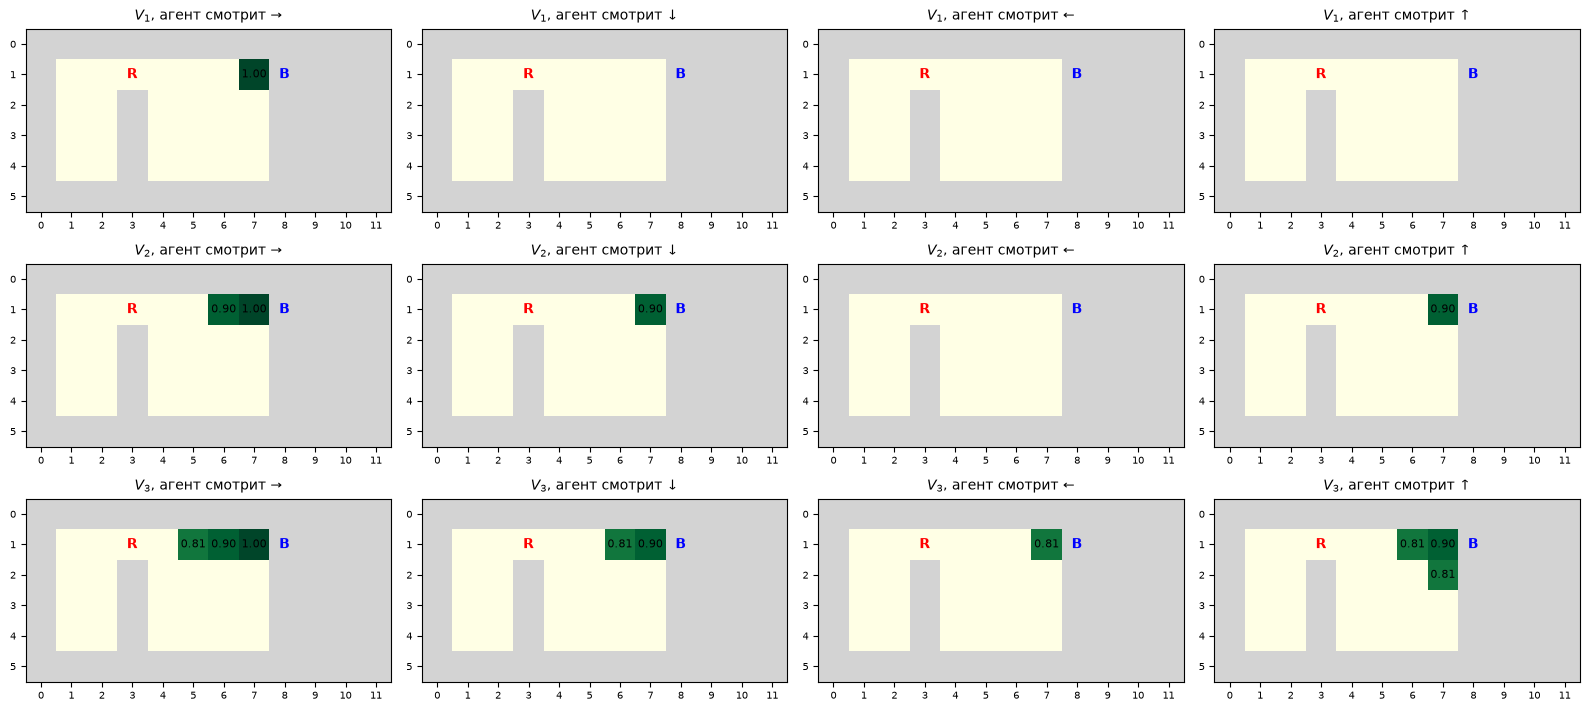

In [18]:
def plot_values(V_list, titles, states, red_open=True):
    u = next(iter(states.values())).unwrapped
    fig, axes = plt.subplots(len(V_list), 4, figsize=(16, 2.4 * len(V_list)))
    axes = np.atleast_2d(axes)
    cmap = plt.get_cmap("YlGn").copy()
    cmap.set_bad("lightgrey")
    for row, (V, title) in enumerate(zip(V_list, titles)):
        for d in range(4):
            grid = np.full((u.height, u.width), np.nan)
            for k, e in states.items():
                (x, y), arrow, is_open = describe(e)
                if is_open == red_open and e.unwrapped.agent_dir == d:
                    grid[y, x] = V.get(k, 0)
            ax = axes[row, d]
            ax.imshow(grid, cmap=cmap, vmin=0, vmax=1)
            for (y, x), v in np.ndenumerate(grid):
                if not np.isnan(v) and v > 0:
                    ax.text(x, y, f"{v:.2f}", ha="center", va="center", fontsize=8)
            # подписи дверей — координаты карты сида 0
            ax.text(3, 1, "R", ha="center", va="center", color="red", fontweight="bold")
            ax.text(8, 1, "B", ha="center", va="center", color="blue", fontweight="bold")
            ax.set_title(f"{title}, агент смотрит {'→↓←↑'[d]}", fontsize=10)
            ax.set_xticks(range(u.width))
            ax.set_yticks(range(u.height))
            ax.tick_params(labelsize=7)
    plt.tight_layout()
    plt.show()


plot_values(history, ["$V_1$", "$V_2$", "$V_3$"], states)

На картинках видно, что ценность появляется у синей двери (`B`) и с каждой итерацией расходится на одну клетку или один поворот назад. При этом значения на «волне» уменьшаются в $\gamma$ раз за шаг: 1 → 0.9 → 0.81.

### Итоги пункта 2

1. Среда детерминированная, поэтому уравнение Беллмана сводится к $V_{i+1}(s) = \max_a [r + \gamma V_i(s')]$ без мат. ожидания. Терминальные состояния имеют $V = 0$.
2. При $\gamma = 0.9$ и $V_0 = 0$:
   - $V_1$ ненулевое только у S\* (перед синей дверью, лицом к ней, красная открыта), $V_1 = 1$;
   - $V_2$ добавляет 3 соседних состояния со значением 0.9;
   - $V_3$ добавляет ещё 5 со значением 0.81.
3. **Ответ:** $V_3 \neq 0$ у 9 состояний (для синей двери в средней строке — у 10), все с открытой красной дверью. Значения $1$, $\gamma$, $\gamma^2$ соответствуют 1, 2 и 3 шагам до успеха.
4. Общий закон: $V_k(s) = \gamma^{d(s)-1}$ при $d(s) \le k$. Каждая итерация продвигает фронт ценности на один шаг от финиша, поэтому для старта в 10 шагах нужно не меньше 10 итераций.
5. Ручной расчёт подтверждён программой: те же 9 состояний и значения; «пустые» действия ответ не меняют.